# Deep Learning Mini Project
## Topic: Chest X-ray medical diagonosis

# 1. Load Datasets

In [26]:
# Cell 1: Upload your Kaggle API token
from google.colab import files

print("Please upload your kaggle.json file:")
files.upload()

# Make directory and move the file
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

print("\nKaggle API token configured.")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json

Kaggle API token configured.


In [27]:
# Cell 2: Download and unzip the pre-sorted dataset
!pip install kaggle -q

print("Downloading dataset...")
# This is the dataset that's already sorted into NORMAL/PNEUMONIA
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

print("Unzipping dataset...")
!unzip -q chest-xray-pneumonia.zip

# The data is now in a folder named 'chest_xray'
# Let's check the contents
!ls -R /content/chest_xray/

Streaming output truncated to the last 5000 lines.
NORMAL2-IM-0388-0001.jpeg	NORMAL2-IM-1293-0001.jpeg
NORMAL2-IM-0389-0001.jpeg	NORMAL2-IM-1294-0001-0001.jpeg
NORMAL2-IM-0390-0001.jpeg	NORMAL2-IM-1294-0001-0002.jpeg
NORMAL2-IM-0391-0001.jpeg	NORMAL2-IM-1294-0001.jpeg
NORMAL2-IM-0392-0001.jpeg	NORMAL2-IM-1295-0001.jpeg
NORMAL2-IM-0393-0001.jpeg	NORMAL2-IM-1296-0001.jpeg
NORMAL2-IM-0394-0001.jpeg	NORMAL2-IM-1300-0001.jpeg
NORMAL2-IM-0395-0001-0001.jpeg	NORMAL2-IM-1301-0001.jpeg
NORMAL2-IM-0395-0001-0002.jpeg	NORMAL2-IM-1302-0001.jpeg
NORMAL2-IM-0395-0001.jpeg	NORMAL2-IM-1303-0001.jpeg
NORMAL2-IM-0396-0001.jpeg	NORMAL2-IM-1304-0001.jpeg
NORMAL2-IM-0397-0001.jpeg	NORMAL2-IM-1305-0001.jpeg
NORMAL2-IM-0399-0001.jpeg	NORMAL2-IM-1306-0001.jpeg
NORMAL2-IM-0401-0001.jpeg	NORMAL2-IM-1307-0001.jpeg
NORMAL2-IM-0402-0001.jpeg	NORMAL2-IM-1308-0001.jpeg
NORMAL2-IM-0403-0001.jpeg	NORMAL2-IM-1310-0001.jpeg
NORMAL2-IM-0404-0001.jpeg	NORMAL2-IM-1311-0001.jpeg
NORMAL2-IM-0406-0001.jpeg	NORMAL2-IM-1314-000

# 2. Preprocess dataset

In [28]:
# Cell 3: Create the Data Loader
import tensorflow as tf

# Define constants from your plan
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Step 3: Implement Data Augmentation
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip("horizontal"),
  tf.keras.layers.RandomRotation(0.1),
  tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

# Define the normalization layer
normalization_layer = tf.keras.layers.Rescaling(1./255)

def load_pipeline(train_dir, val_dir, test_dir):

    # Step 2: Build the Basic Data Loader
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        label_mode='categorical', # Use 'categorical' for two classes
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        label_mode='categorical',
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir,
        label_mode='categorical',
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Step 4: Create the Final, High-Performance Pipeline

    # Apply augmentation to the training dataset ONLY.
    # Note: We apply augmentation *before* normalization as specified
    train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                            num_parallel_calls=tf.data.AUTOTUNE)

    # Apply normalization to all datasets.
    train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y),
                            num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y),
                          num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y),
                          num_parallel_calls=tf.data.AUTOTUNE)

    # Use prefetch for performance on all datasets
    train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

    print("Data pipelines created and optimized.")
    return train_ds, val_ds, test_ds

# --- Test the function ---
# These paths match the folders created in Cell 2
TRAIN_PATH = '/content/chest_xray/train'
VAL_PATH = '/content/chest_xray/val' # Note: the folder is 'val', not 'validation'
TEST_PATH = '/content/chest_xray/test'

# Load the datasets
train_dataset, val_dataset, test_dataset = load_pipeline(TRAIN_PATH, VAL_PATH, TEST_PATH)

# Print a sample batch shape to confirm it works
for images, labels in train_dataset.take(1):
    print("\n--- Test Batch ---")
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Data pipelines created and optimized.

--- Test Batch ---
Images shape: (32, 224, 224, 3)
Labels shape: (32, 2)


# 3. Building the model

In [29]:
# Cell 4: Model Building Factory (Role 2)
import tensorflow as tf
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import time
import pandas as pd
import matplotlib.pyplot as plt

# --- Step 1: Get the Data (from Role 1) ---
# We assume train_dataset, val_dataset, and test_dataset are in memory from Cell 3.
print("--- Using Data Pipelines from Role 1 ---")

# --- Model Building Function ---
def build_scout_model(base_model_fn, name):
    """
    Builds and compiles a new model for scouting.
    - base_model_fn: The Keras application (e.g., VGG16, ResNet50)
    - name: The string name for the model
    """
    # 1. Load the pre-trained base
    base_model = base_model_fn(input_shape=(224, 224, 3),
                              include_top=False,
                              weights='imagenet')

    # 2. Freeze the base model's layers
    base_model.trainable = False

    # 3. Build the new model on top
    model = Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.5),
        Dense(2, activation='softmax') # 2 units: NORMAL/PNEUMONIA
    ], name=name)

    # 4. Compile the model
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=[
            CategoricalAccuracy(name='accuracy'),
            Precision(name='precision'),
            Recall(name='recall')
        ]
    )

    print(f"--- Model {name} Built ---")
    model.summary()
    return model

# --- Build all 3 models ---
model_vgg = build_scout_model(VGG16, name="VGG16")
model_resnet = build_scout_model(ResNet50, name="ResNet50")
model_inception = build_scout_model(InceptionV3, name="InceptionV3")

--- Using Data Pipelines from Role 1 ---
--- Model VGG16 Built ---


Model: "VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,714 (56.14 MB)

 Trainable params: 1,026 (4.01 KB)

...

Model: "InceptionV3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,806,882 (83.19 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
# Cell 5: Train All Models (Steps 2 & 3)

EPOCHS = 10
models_to_train = [
    ("VGG16", model_vgg),
    ("ResNet50", model_resnet),
    ("InceptionV3", model_inception)
]

# This dictionary will hold the training history and time for each model
scout_results = {}

# Define a standard EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss',
                             patience=3, # Stop if no improvement for 3 epochs
                             restore_best_weights=True)

for name, model in models_to_train:
    print(f"\n--- SCOUTING MODEL: {name} ---")

    # Define a checkpoint to save the best version of this model
    checkpoint_callback = ModelCheckpoint(
        filepath=f"{name}_scout_best.keras",
        monitor='val_accuracy',
        save_best_only=True
    )

    # Time the training
    start_time = time.time()

    # Train the model
    history = model.fit(
        train_dataset,
        epochs=EPOCHS,
        validation_data=val_dataset,
        callbacks=[early_stopping, checkpoint_callback]
    )

    end_time = time.time()

    # Store results
    scout_results[name] = {
        'history': history,
        'train_time_sec': round(end_time - start_time, 2),
        'best_model_file': f"{name}_scout_best.keras"
    }

    print(f"--- {name} Training Complete in {scout_results[name]['train_time_sec']}s ---")


--- SCOUTING MODEL: VGG16 ---
Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 558ms/step - accuracy: 0.6278 - loss: 0.8085 - precision: 0.6278 - recall: 0.6278 - val_accuracy: 0.5000 - val_loss: 0.6639 - val_precision: 0.5000 - val_recall: 0.5000
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 96s 588ms/step - accuracy: 0.7959 - loss: 0.4208 - precision: 0.7959 - recall: 0.7959 - val_accuracy: 0.5625 - val_loss: 0.6208 - val_precision: 0.5625 - val_recall: 0.5625
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 74s 449ms/step - accuracy: 0.8432 - loss: 0.3549 - precision: 0.8432 - recall: 0.8432 - val_accuracy: 0.6250 - val_loss: 0.6326 - val_precision: 0.6250 - val_recall: 0.6250
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 74s 452ms/step - accuracy: 0.8596 - loss: 0.3234 - precision: 0.8596 - recall: 0.8596 - val_accuracy: 0.6250 - val_loss: 0.6122 - val_precision: 0.6250 - val_recall: 0.6250
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 74s 452ms/step - accuracy: 0.8679 - loss: 0.3011 - precision: 0.8679 - recal

# 4. Perform avaluation metrics


--- Evaluating Models on Unseen Test Data ---
Loading best VGG16 model from VGG16_scout_best.keras...
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 204ms/step - accuracy: 0.7611 - loss: 0.5194 - precision: 0.7611 - recall: 0.7611
Loading best ResNet50 model from ResNet50_scout_best.keras...
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 0.4097 - loss: 0.7373 - precision: 0.4097 - recall: 0.4097
Loading best InceptionV3 model from InceptionV3_scout_best.keras...
20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 260ms/step - accuracy: 0.6746 - loss: 0.7175 - precision: 0.6746 - recall: 0.6746

--- FINAL SCOUTING REPORT ---
| Model       |   Test Accuracy |   Test Precision |   Test Recall |   Test Loss |   Train Time (sec) |
|:------------|----------------:|-----------------:|--------------:|------------:|-------------------:|
| VGG16       |          0.8413 |           0.8413 |        0.8413 |      0.3884 |           655.4300 |
| ResNet50    |          0.6859 |           0.6859 |        0.6859 |      0.5760 |    

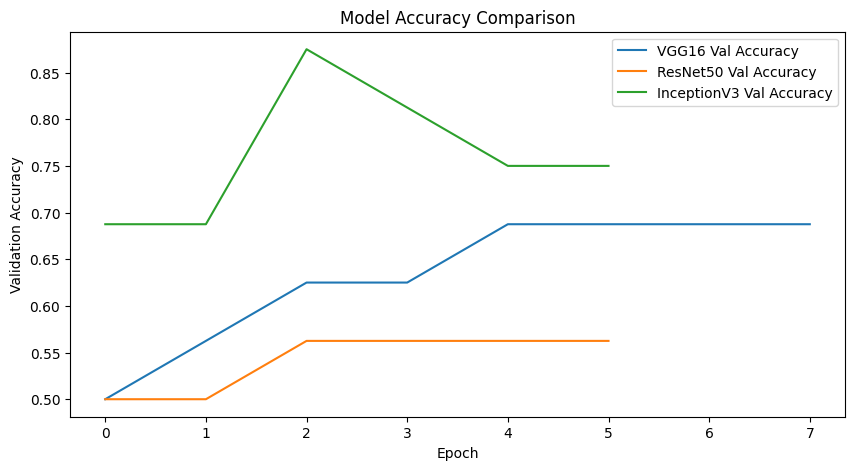

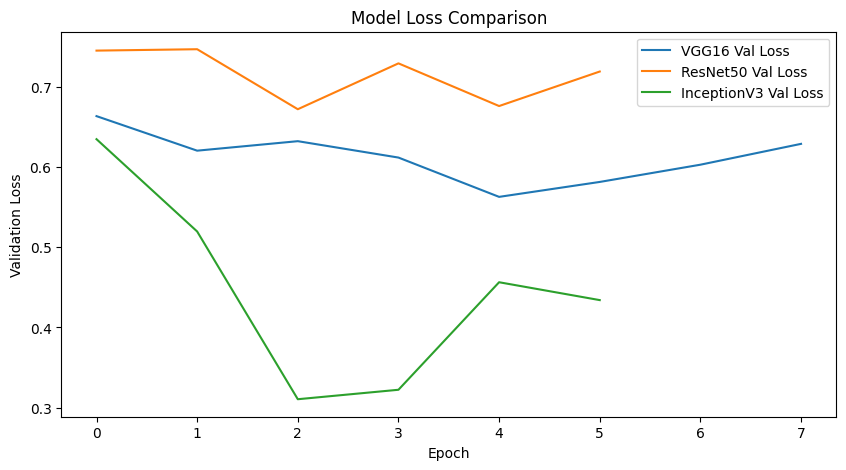

In [ ]:
# Cell 6: Pick the Winner (Step 4: Evaluation & Recommendation)

print("\n--- Evaluating Models on Unseen Test Data ---")

final_report = []

for name, results in scout_results.items():
    # 1. Load the best saved model
    print(f"Loading best {name} model from {results['best_model_file']}...")
    best_model = load_model(results['best_model_file'])

    # 2. Evaluate on the test_dataset
    test_loss, test_acc, test_prec, test_recall = best_model.evaluate(test_dataset)

    # 3. Store test results
    final_report.append({
        "Model": name,
        "Test Accuracy": round(test_acc, 4),
        "Test Precision": round(test_prec, 4),
        "Test Recall": round(test_recall, 4),
        "Test Loss": round(test_loss, 4),
        "Train Time (sec)": results['train_time_sec']
    })

# --- Create and Print Final Comparison Table ---
report_df = pd.DataFrame(final_report).set_index("Model")
print("\n--- FINAL SCOUTING REPORT ---")
print(report_df.to_markdown(floatfmt=".4f"))

# --- Create Comparison Plots ---
print("\n--- Plotting Training Histories ---")

# Plot Accuracy
plt.figure(figsize=(10, 5))
for name, results in scout_results.items():
    plt.plot(results['history'].history['val_accuracy'], label=f"{name} Val Accuracy")
plt.title('Model Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.savefig('scout_accuracy_comparison.png')
print("Saved accuracy comparison plot to scout_accuracy_comparison.png")

# Plot Loss
plt.figure(figsize=(10, 5))
for name, results in scout_results.items():
    plt.plot(results['history'].history['val_loss'], label=f"{name} Val Loss")
plt.title('Model Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.savefig('scout_loss_comparison.png')
print("Saved loss comparison plot to scout_loss_comparison.png")

# --- 🏛️ Role 2 Recommendation ---
print("\n\n--- 🏛️ MODEL SCOUT RECOMMENDATION ---")
# Find the best model based on Test Accuracy
best_model_name = report_df['Test Accuracy'].idxmax()
best_model_stats = report_df.loc[best_model_name]

print(f"Recommendation: {best_model_name}")
print(f"Justification: {best_model_name} achieved the highest Test Accuracy of {best_model_stats['Test Accuracy']:.4f}.")
print(f"It also scored a Precision of {best_model_stats['Test Precision']:.4f} and Recall of {best_model_stats['Test Recall']:.4f}, with a training time of {best_model_stats['Train Time (sec)']} seconds.")
print("This model provides the best balance of performance for the 'feature extraction' phase and should be the one we focus on for further fine-tuning.")

In [ ]:

!pip install keras-tuner -q

In [ ]:
import keras_tuner as kt
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.losses import CategoricalCrossentropy

print("\n--- Starting Hyperparameter Tuning for VGG16 ---")


--- Starting Hyperparameter Tuning for VGG16 ---


In [ ]:
# --- Step 1: Define Model Builder Function for KerasTuner ---
def build_vgg16_tuned_model(hp):
    base_model = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
    base_model.trainable = False

    model = Sequential()
    model.add(base_model)
    model.add(GlobalAveragePooling2D())

    # Tune dropout rate
    dropout_rate = hp.Float('dropout_rate', min_value=0.3, max_value=0.7, step=0.1)
    model.add(Dropout(dropout_rate))

    # Output layer
    model.add(Dense(2, activation='softmax'))

    # Tune optimizer and learning rate
    hp_optimizer = hp.Choice('optimizer', ['adam', 'rmsprop'])
    hp_learning_rate = hp.Choice('learning_rate', [1e-4, 1e-3, 5e-4])

    if hp_optimizer == 'adam':
        optimizer = Adam(learning_rate=hp_learning_rate)
    else:
        optimizer = RMSprop(learning_rate=hp_learning_rate)

    model.compile(
        optimizer=optimizer,
        loss=CategoricalCrossentropy(),
        metrics=['accuracy', 'precision', 'recall']
    )

    return model

In [ ]:
# --- Step 2: Create the Tuner ---
tuner = kt.Hyperband(
    build_vgg16_tuned_model,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='vgg16_tuning',
    project_name='chest_xray_vgg16'
)


In [ ]:
# --- Step 3: Early Stopping for Tuning ---
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# --- Step 4: Run the Tuner ---
tuner.search(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[stop_early]
)

Trial 30 Complete [00h 05m 12s]
val_accuracy: 0.5

Best val_accuracy So Far: 0.75
Total elapsed time: 02h 24m 05s


In [ ]:
# --- Step 5: Get the Best Hyperparameters ---
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"""
Best Hyperparameters Found:
- Optimizer: {best_hps.get('optimizer')}
- Learning Rate: {best_hps.get('learning_rate')}
- Dropout Rate: {best_hps.get('dropout_rate')}
""")



Best Hyperparameters Found:
- Optimizer: adam
- Learning Rate: 0.001
- Dropout Rate: 0.3



In [ ]:
# --- Step 7: Evaluate Tuned Model ---
print("\n--- Evaluating Tuned VGG16 Model ---")
tuned_loss, tuned_acc, tuned_prec, tuned_recall = tuned_vgg16.evaluate(test_dataset)

print(f"""
Tuned VGG16 Performance on Test Set:
- Accuracy: {tuned_acc:.4f}
- Precision: {tuned_prec:.4f}
- Recall: {tuned_recall:.4f}
- Loss: {tuned_loss:.4f}
""")


--- Evaluating Tuned VGG16 Model ---
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 166ms/step - accuracy: 0.7296 - loss: 0.5659 - precision: 0.7296 - recall: 0.7296

Tuned VGG16 Performance on Test Set:
- Accuracy: 0.8269
- Precision: 0.8269
- Recall: 0.8269
- Loss: 0.4065



In [ ]:
# --- Step 8: Save Final Tuned Model ---
tuned_vgg16.save('VGG16_Tuned_Best.keras')
print("Saved tuned model as VGG16_Tuned_Best.keras")

Saved tuned model as VGG16_Tuned_Best.keras


--- Role 3: Final Model Evaluation ---
Successfully loaded 'VGG16_Tuned_Best.keras'

Evaluating on the unseen test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 200ms/step - accuracy: 0.7296 - loss: 0.5659 - precision: 0.7296 - recall: 0.7296

--- FINAL TUNED MODEL PERFORMANCE ---
     Test Accuracy: 82.69%
     Test Precision: 0.8269
     Test Recall: 0.8269
     Test Loss: 0.4065

Loading base test dataset to get class names...
Found 624 files belonging to 2 classes.
Class names found: ['NORMAL', 'PNEUMONIA']
Generating predictions for classification report...

--- Classification Report ---
              precision    recall  f1-score   support

      NORMAL       0.93      0.59      0.72       234
   PNEUMONIA       0.80      0.97      0.88       390

    accuracy                           0.83       624
   macro avg       0.86      0.78      0.80       624
weighted avg       0.84      0.83      0.82       624


--- Generating Confusion Matrix ---
Confusion matrix saved to 'final_tuned_confus

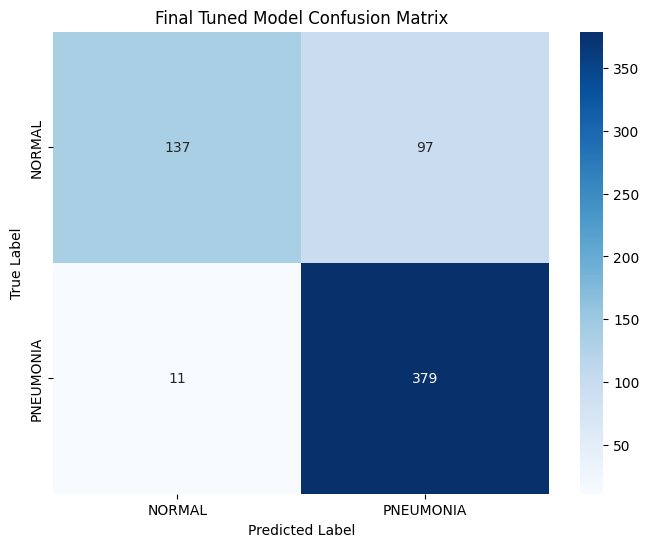

In [ ]:
# Cell 17: Role 3 - Final Evaluation & Reporting
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

print("--- Role 3: Final Model Evaluation ---")

# --- 1. Load the Final Tuned Model ---
# This is the model saved by your Cell 16
try:
    final_model = load_model('VGG16_Tuned_Best.keras')
    print("Successfully loaded 'VGG16_Tuned_Best.keras'")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Please ensure Cell 16 has been run successfully.")
    raise

# --- 2. Get Overall Test Metrics ---
# We use the 'test_dataset' from Role 1 (Cell 3)
print("\nEvaluating on the unseen test set...")
final_loss, final_acc, final_prec, final_recall = final_model.evaluate(test_dataset)

print("\n--- FINAL TUNED MODEL PERFORMANCE ---")
print(f"     Test Accuracy: {final_acc*100:.2f}%")
print(f"     Test Precision: {final_prec:.4f}")
print(f"     Test Recall: {final_recall:.4f}")
print(f"     Test Loss: {final_loss:.4f}")

# --- 3. Get Class Names (Fixing the AttributeError) ---
# The .class_names attribute is lost after .map() and .prefetch().
# We load the base dataset (like in Cell 3) just to get the names.
print("\nLoading base test dataset to get class names...")
base_test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_PATH, # This global variable was defined in Cell 3
    label_mode='categorical',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)
class_names = base_test_ds.class_names
print(f"Class names found: {class_names}")

# --- 4. Get All Predictions for Detailed Report ---
print("Generating predictions for classification report...")
y_true = []
y_pred_probs = []

for images, labels in test_dataset.as_numpy_iterator():
    y_true.extend(np.argmax(labels, axis=1))
    preds = final_model.predict_on_batch(images)
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

# --- 5. Print Classification Report ---
print("\n--- Classification Report ---")
# This shows precision, recall, and f1-score for BOTH classes
print(classification_report(y_true, y_pred, target_names=class_names))

# --- 6. Plot Confusion Matrix ---
print("\n--- Generating Confusion Matrix ---")
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Final Tuned Model Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('final_tuned_confusion_matrix.png')
print("Confusion matrix saved to 'final_tuned_confusion_matrix.png'")

In [ ]:
# Cell 18: Export Final Model
from google.colab import files

print("\n--- Exporting Final Tuned Model ---")
print("This will trigger a download in your browser.")

files.download('VGG16_Tuned_Best.keras')

print("\nDownload complete.")


--- Exporting Final Tuned Model ---
This will trigger a download in your browser.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download complete.


# 5. Perform additional Evaluation metrics

In [5]:
!pip install keras-tuner -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 6.6 MB/s eta 0:00:00


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

Streaming output truncated to the last 5000 lines.
NORMAL2-IM-0395-0001.jpeg	NORMAL2-IM-1303-0001.jpeg
NORMAL2-IM-0396-0001.jpeg	NORMAL2-IM-1304-0001.jpeg
NORMAL2-IM-0397-0001.jpeg	NORMAL2-IM-1305-0001.jpeg
NORMAL2-IM-0399-0001.jpeg	NORMAL2-IM-1306-0001.jpeg
NORMAL2-IM-0401-0001.jpeg	NORMAL2-IM-1307-0001.jpeg
NORMAL2-IM-0402-0001.jpeg	NORMAL2-IM-1308-0001.jpeg
NORMAL2-IM-0403-0001.jpeg	NORMAL2-IM-1310-0001.jpeg
NORMAL2-IM-0404-0001.jpeg	NORMAL2-IM-1311-0001.jpeg
NORMAL2-IM-0406-0001.jpeg	NORMAL2-IM-1314-0001.jpeg
NORMAL2-IM-0407-0001.jpeg	NORMAL2-IM-1315-0001.jpeg
NORMAL2-IM-0408-0001.jpeg	NORMAL2-IM-1316-0001.jpeg
NORMAL2-IM-0409-0001.jpeg	NORMAL2-IM-1317-0001.jpeg
NORMAL2-IM-0410-0001.jpeg	NORMAL2-IM-1318-0001.jpeg
NORMAL2-IM-0412-0001.jpeg	NORMAL2-IM-1319-0001.jpeg
NORMAL2-IM-0413-0001.jpeg	NORMAL2-IM-1320-0001.jpeg
NORMAL2-IM-0414-0001.jpeg	NORMAL2-IM-1321-0001.jpeg
NORMAL2-IM-0415-0001.jpeg	NORMAL2-IM-1322-0001.jpeg
NORMAL2-IM-0416-0001-0001.jpeg	NORMAL2-IM-1323-0001.jpeg
NORMAL2-

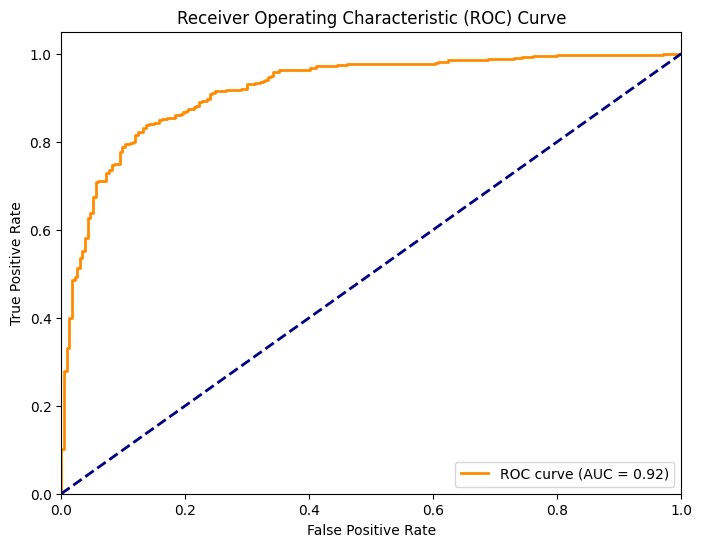

ROC curve plot saved to 'tuned_model_roc_curve.png'


In [31]:
# Cell 1: Upload your Kaggle API token (Included here to ensure token is configured)
from google.colab import files
import os # Import os module

print("Please upload your kaggle.json file:")
# Check if kaggle.json already exists in the correct location
if not os.path.exists('/root/.kaggle/kaggle.json'):
    uploaded = files.upload()
    for fn in uploaded.keys():
        print('User uploaded file "{name}" with length {length} bytes'.format(
            name=fn, length=len(uploaded[fn])))

    # Make directory and move the file
    !mkdir -p ~/.kaggle
    !mv kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

    print("\nKaggle API token configured.")
else:
    print("Kaggle API token already configured.")


# Cell 2: Download and unzip the pre-sorted dataset
!pip install kaggle -q

print("Downloading dataset...")
# This is the dataset that's already sorted into NORMAL/PNEUMONIA
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

print("Unzipping dataset...")
# Check if the directory already exists before unzipping
if not os.path.exists('/content/chest_xray'):
    !unzip -q chest-xray-pneumonia.zip
    print("Dataset unzipped.")
else:
    print("Dataset already unzipped.")


# The data is now in a folder named 'chest_xray'
# Let's check the contents
!ls -R /content/chest_xray/


# Auc-Roc
from sklearn.metrics import RocCurveDisplay, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import load_model
import tensorflow as tf # Import tensorflow to use image_dataset_from_directory and AUTOTUNE

# --- Data Loading Pipeline (Included here to ensure test_dataset is defined) ---
# Define constants from your plan
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
TRAIN_PATH = '/content/chest_xray/train'
VAL_PATH = '/content/chest_xray/val'
TEST_PATH = '/content/chest_xray/test'

# Step 3: Implement Data Augmentation (Needed by load_pipeline)
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip("horizontal"),
  tf.keras.layers.RandomRotation(0.1),
  tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

# Define the normalization layer (Needed by load_pipeline)
normalization_layer = tf.keras.layers.Rescaling(1./255)

def load_pipeline(train_dir, val_dir, test_dir):

    # Step 2: Build the Basic Data Loader
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        label_mode='categorical', # Use 'categorical' for two classes
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir,
        label_mode='categorical',
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir,
        label_mode='categorical',
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # Step 4: Create the Final, High-Performance Pipeline

    # Apply augmentation to the training dataset ONLY.
    # Note: We apply augmentation *before* normalization as specified
    train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                            num_parallel_calls=tf.data.AUTOTUNE)

    # Apply normalization to all datasets.
    train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y),
                            num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y),
                          num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y),
                          num_parallel_calls=tf.data.AUTOTUNE)

    # Use prefetch for performance on all datasets
    train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

    print("Data pipelines created and optimized.")
    return train_ds, val_ds, test_ds

# Load the datasets
train_dataset, val_dataset, test_dataset = load_pipeline(TRAIN_PATH, VAL_PATH, TEST_PATH)
# --- End Data Loading Pipeline ---


# --- Load the Final Tuned Model ---
# Assuming the model was saved as 'VGG16_Tuned_Best.keras' in a previous step.
try:
    final_model = load_model('VGG16_Tuned_Best.keras')
    print("Successfully loaded 'VGG16_Tuned_Best.keras'")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Please ensure the final tuned model has been saved.")
    # You might want to add a way to rebuild the model if loading fails and the necessary variables are available.
    # For now, we'll raise the error.
    raise

# --- Get True Labels and Predicted Probabilities ---
print("\nGetting true labels and predictions for AUC calculation...")
y_true = []
y_pred_probs = []

# Iterate over the test_dataset to get true labels and predictions
# We need to get the raw probabilities for AUC calculation
for images, labels in test_dataset.as_numpy_iterator():
    y_true.extend(np.argmax(labels, axis=1))
    preds = final_model.predict_on_batch(images)
    y_pred_probs.extend(preds[:, 1]) # Get probability of the positive class (PNEUMONIA)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)


# --- For binary classification ---
if len(set(y_true)) == 2:
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
    auc_score = auc(fpr, tpr)

    print(f"\nCalculated AUC: {auc_score:.4f}")

    plt.figure(figsize=(8,6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % auc_score)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.savefig('tuned_model_roc_curve.png')
    plt.show()

print("ROC curve plot saved to 'tuned_model_roc_curve.png'")

In [33]:
# sensitivity and specification

import numpy as np
from sklearn.metrics import confusion_matrix
from tensorflow.keras.models import load_model
import tensorflow as tf # Import tensorflow for dataset

# --- Load the Final Tuned Model ---
# Assuming the model was saved as 'VGG16_Tuned_Best.keras'
try:
    final_model = load_model('VGG16_Tuned_Best.keras')
    print("Successfully loaded 'VGG16_Tuned_Best.keras'")
except Exception as e:
    print(f"Error loading model: {e}")
    print("Please ensure the final tuned model has been saved.")
    raise

# --- Data Loading Pipeline (Included here to ensure test_dataset is defined) ---
# Define constants and load pipeline components if not already defined
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
TRAIN_PATH = '/content/chest_xray/train'
VAL_PATH = '/content/chest_xray/val'
TEST_PATH = '/content/chest_xray/test'

# Data augmentation and normalization layers (needed by load_pipeline)
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip("horizontal"),
  tf.keras.layers.RandomRotation(0.1),
  tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")
normalization_layer = tf.keras.layers.Rescaling(1./255)


def load_pipeline(train_dir, val_dir, test_dir):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, label_mode='categorical', image_size=IMG_SIZE, batch_size=BATCH_SIZE
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir, label_mode='categorical', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
    )
    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir, label_mode='categorical', image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
    )

    train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=tf.data.AUTOTUNE)

    train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
    print("Data pipelines created and optimized.")
    return train_ds, val_ds, test_ds

# Load the datasets if not already in memory
try:
  test_dataset # Check if test_dataset exists
except NameError:
  print("Loading datasets...")
  train_dataset, val_dataset, test_dataset = load_pipeline(TRAIN_PATH, VAL_PATH, TEST_PATH)
# --- End Data Loading Pipeline ---

# --- Get True Labels and Predicted Labels ---
print("\nGenerating predictions for confusion matrix...")
y_true = []
y_pred = []

for images, labels in test_dataset.as_numpy_iterator():
    y_true.extend(np.argmax(labels, axis=1))
    preds = final_model.predict_on_batch(images)
    y_pred.extend(np.argmax(preds, axis=1)) # Get predicted class index

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# --- Calculate Confusion Matrix ---
print("Calculating confusion matrix...")
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# --- Calculate Sensitivity and Specificity ---
# Assuming binary classification, cm is [[TN, FP], [FN, TP]]
if cm.shape == (2, 2):
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    print(f"\nSensitivity (Recall for Positive Class): {sensitivity:.4f}")
    print(f"Specificity (Recall for Negative Class): {specificity:.4f}")
else:
    print("\nConfusion matrix is not 2x2. Cannot calculate sensitivity and specificity this way.")

Successfully loaded 'VGG16_Tuned_Best.keras'

Generating predictions for confusion matrix...
Calculating confusion matrix...
Confusion Matrix:
 [[137  97]
 [ 11 379]]

Sensitivity (Recall for Positive Class): 0.9718
Specificity (Recall for Negative Class): 0.5855


In [34]:
# mcc
from sklearn.metrics import matthews_corrcoef

mcc = matthews_corrcoef(y_true, y_pred)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")

Matthews Correlation Coefficient (MCC): 0.6343


In [35]:
# log-loss
from sklearn.metrics import log_loss

loss_value = log_loss(y_true, y_pred_probs)
print(f"Log Loss: {loss_value:.4f}")

Log Loss: 0.4065


In [36]:
# summary of all metrics
import pandas as pd

metrics_summary = {
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'Specificity', 'F1 Score', 'AUC', 'MCC', 'Log Loss'],
    'Value': [
        (y_pred == y_true).mean(),
        precision_score(y_true, y_pred),
        recall_score(y_true, y_pred),
        specificity,
        f1_score(y_true, y_pred),
        auc_score,
        mcc,
        loss_value
    ]
}

metrics_df = pd.DataFrame(metrics_summary)
print("\n--- Evaluation Metrics Summary ---\n")
print(metrics_df)


--- Evaluation Metrics Summary ---

                 Metric     Value
0              Accuracy  0.826923
1             Precision  0.796218
2  Recall (Sensitivity)  0.971795
3           Specificity  0.585470
4              F1 Score  0.875289
5                   AUC  0.920480
6                   MCC  0.634260
7              Log Loss  0.406519


# 6. Implement a UI